# Figure source — CUBS proxy_raw training-set distribution

This figure notebook loads the processed CUBS cache created by Notebook 01 and plots the distribution of `proxy_raw` for the 1,740 CUBS training images. It does not reprocess images or rerun SSL.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import pickle
import numpy as np
import matplotlib.pyplot as plt


Mounted at /content/drive


In [2]:
# Processed CUBS cache produced by Notebook 01
CACHE_PATH = (
    '/content/drive/MyDrive/IJEPA_Carotid_ViTS16/'
    'clean_2840_20260930/manifests/cubs_processed_split_clean.pkl'
)

assert os.path.exists(CACHE_PATH), f'Cache not found: {CACHE_PATH}'

with open(CACHE_PATH, 'rb') as f:
    cache = pickle.load(f)

cubs_train_records = cache['cubs_train_records']
saved_threshold = float(cache['proxy_threshold'])

proxy_raw = np.asarray(
    [r['proxy_raw'] for r in cubs_train_records],
    dtype=float
)

q50 = float(np.median(proxy_raw))

# Provenance / safety checks
assert len(proxy_raw) == 1740, f'Expected 1740 training images, found {len(proxy_raw)}'
assert np.isclose(q50, saved_threshold), (q50, saved_threshold)

n0 = int(np.sum(proxy_raw < q50))
n1 = int(np.sum(proxy_raw >= q50))

print('Loaded:', CACHE_PATH)
print('Training images:', len(proxy_raw))
print(f'q50 (median): {q50:.4f}')
print('Label 0 (proxy_raw < q50):', n0)
print('Label 1 (proxy_raw >= q50):', n1)


Loaded: /content/drive/MyDrive/IJEPA_Carotid_ViTS16/clean_2840_20260930/manifests/cubs_processed_split_clean.pkl
Training images: 1740
q50 (median): 60.2658
Label 0 (proxy_raw < q50): 870
Label 1 (proxy_raw >= q50): 870


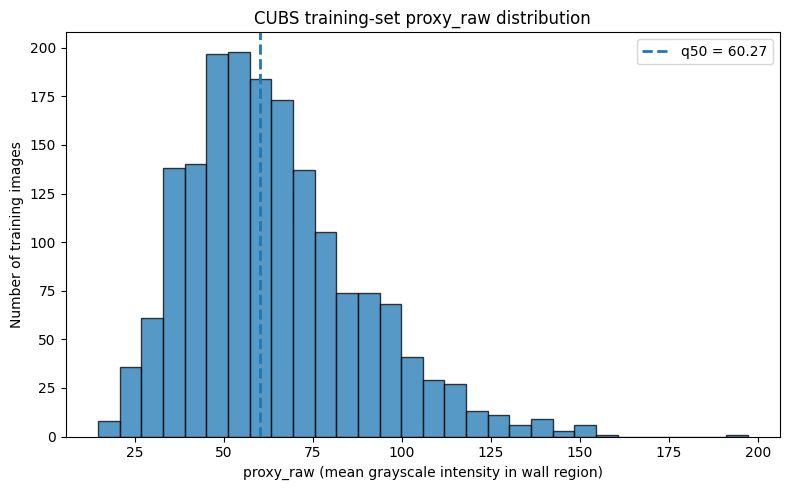

In [3]:
# Real histogram from the 1,740 processed CUBS training images
fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(proxy_raw, bins=30, edgecolor='black', alpha=0.75)
ax.axvline(
    q50,
    linestyle='--',
    linewidth=2,
    label=f'q50 = {q50:.2f}'
)

ax.set_xlabel('proxy_raw (mean grayscale intensity in wall region)')
ax.set_ylabel('Number of training images')
ax.set_title('CUBS training-set proxy_raw distribution')
ax.legend()

fig.tight_layout()
plt.show()


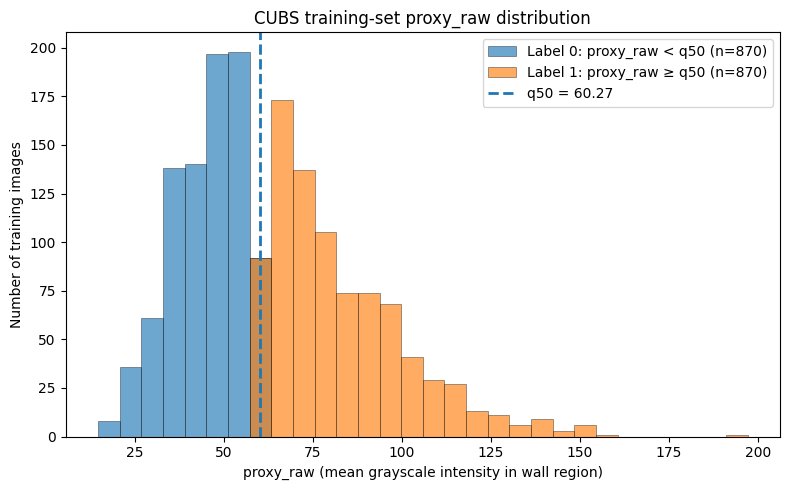

In [5]:
# Real two-colour histogram from the 1,740 CUBS training images

fig, ax = plt.subplots(figsize=(8, 5))

# Common bin edges for both classes
bins = np.linspace(proxy_raw.min(), proxy_raw.max(), 31)

label0 = proxy_raw[proxy_raw < q50]
label1 = proxy_raw[proxy_raw >= q50]

ax.hist(
    label0,
    bins=bins,
    alpha=0.65,
    edgecolor='black',
    linewidth=0.4,
    label=f'Label 0: proxy_raw < q50 (n={len(label0)})'
)

ax.hist(
    label1,
    bins=bins,
    alpha=0.65,
    edgecolor='black',
    linewidth=0.4,
    label=f'Label 1: proxy_raw ≥ q50 (n={len(label1)})'
)

ax.axvline(
    q50,
    linestyle='--',
    linewidth=2,
    label=f'q50 = {q50:.2f}'
)

ax.set_xlabel('proxy_raw (mean grayscale intensity in wall region)')
ax.set_ylabel('Number of training images')
ax.set_title('CUBS training-set proxy_raw distribution')

ax.legend()
fig.tight_layout()
plt.show()

In [6]:
# Optional: save a high-resolution copy to Google Drive
OUTPUT_PATH = (
    '/content/drive/MyDrive/IJEPA_Carotid_ViTS16/'
    'clean_2840_20260930/review/CUBS_proxy_raw_histogram.png'
)

fig.savefig(OUTPUT_PATH, dpi=300, bbox_inches='tight')
print('Saved:', OUTPUT_PATH)


Saved: /content/drive/MyDrive/IJEPA_Carotid_ViTS16/clean_2840_20260930/review/CUBS_proxy_raw_histogram.png
